# 02 · An observational study: does quitting smoking cause weight gain, and for whom?

People who quit smoking often gain weight, and the gain matters: it is one of the most common reasons people give for not quitting, and it is a health risk of its own. How much of the gain is caused by quitting cannot be settled by a randomized trial, since no one can be assigned to keep smoking. It has to be estimated from observational data, where people chose for themselves whether to quit, and where the people who quit differed from those who did not in age, in how much they smoked, in their weight and in other ways that also affect how weight changes.

This notebook takes the estimators of [notebook 01](01_effects_with_a_known_answer.ipynb) to such a study: the NHEFS data that Hernán and Robins analyse throughout *Causal Inference: What If* (Chapman & Hall/CRC, 2020). 1,629 adult cigarette smokers were examined in 1971 and again in 1982. Between the two visits some quit smoking; for each person the data record whether they quit, their weight change, and the characteristics measured in 1971 that the book treats as the confounders.

Unlike in notebook 01, no one's true effect is known here. What is known is the book's own estimate of the average effect, about 3.4 to 3.5 kg, and that serves as the first anchor. Beyond it, a real study has to rely on checks that need no ground truth: how well each model predicts held-out people, whether weighting balances the two groups, whether estimated differences between people survive a test, and how strong an unmeasured confounder would have to be to change the conclusion. The notebook answers, in order:

1. **How different were quitters from non-quitters,** and how far off is the plain comparison?
2. **Can the book's published estimates be reproduced** with its own models?
3. **What do the doubly robust estimators say with linear models, tuned gradient boosting and TabPFN,** and how well does each model predict people it has not seen?
4. **Do the weights balance the two groups,** and do the groups overlap?
5. **Does the effect differ between people,** and is that difference real or noise?
6. **How strong would an unmeasured confounder have to be** to explain the effect away?

## 1. Setup

`helper.py` loads the data, builds the book's model terms and draws the plots; the estimators and checks come from `tabicllab.treatment_effects`. Like notebook 01, this notebook fits TabPFN many times and is executed on a GPU pod. With `TE_SMOKE=1` it runs on a random subset of 300 people with a light TabPFN, to check that every cell works.

In [1]:
import time

import doubleml as dml
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

import helper
from helper import NHEFS_COVARIATES, base_learners, load_nhefs, textbook_design
from tabicllab.treatment_effects import (
    aipw_ate,
    blp_test,
    dr_learner,
    dr_pseudo_outcome,
    fit_nuisances,
    fold_ids,
    gates,
    ipw_ate,
    naive_difference,
    overlap_summary,
    standardized_differences,
    t_learner,
    x_learner,
)

helper.configure_plots(plots=True)
tabpfn_version = helper.init_tabpfn()
N_FOLDS = helper.N_FOLDS
SPLIT_SEEDS = [0, 1] if helper.SMOKE else [0, 1, 2, 3, 4]

LABELS = {
    "sex": "female", "race": "not white", "age": "age, years", "education": "education level",
    "smokeintensity": "cigarettes per day", "smokeyrs": "years of smoking", "exercise": "little exercise",
    "active": "inactive", "wt71": "weight in 1971, kg",
}

TabPFN v3.5 weights, running on NVIDIA A40


## 2. The data

The book's analysis uses the 1,566 people whose weight was measured in 1982; 63 more have no 1982 weight. The treatment is `qsmk`, 1 for people who quit smoking between the visits. The outcome is `wt82_71`, the weight change from 1971 to 1982 in kg. The confounders, all measured in 1971, are the nine the book adjusts for: sex, race, age, education (five levels), cigarettes per day, years of smoking, how much recreational exercise and how much daily activity the person had (three levels each), and weight.

The table gives each group's averages. The last column, the *standardized mean difference*, is the difference between the groups' means divided by the covariate's spread; it puts all covariates on one scale, and a common rule of thumb reads an absolute value below 0.1 as balanced.

In [2]:
nhefs = load_nhefs()
if helper.N_MEMBERS < len(nhefs):            # smoke runs, or TE_MEMBERS, use a random subset
    nhefs = nhefs.sample(helper.N_MEMBERS, random_state=0)

t = nhefs["qsmk"].to_numpy()
y = nhefs["wt82_71"].to_numpy()
X_raw = nhefs[NHEFS_COVARIATES].to_numpy(dtype=float)
X_book = textbook_design(nhefs).to_numpy(dtype=float)
print(f"{len(nhefs)} people, {t.sum()} of whom quit smoking")

raw_balance = pd.Series(standardized_differences(X_raw, t, names=NHEFS_COVARIATES))
summary = nhefs.groupby("qsmk")[NHEFS_COVARIATES].mean().T.rename(columns={0: "did not quit", 1: "quit"})
summary["standardized difference"] = raw_balance
summary.rename(index=LABELS).round(2)

1566 people, 403 of whom quit smoking


qsmk,did not quit,quit,standardized difference
female,0.53,0.45,-0.16
not white,0.15,0.09,-0.18
"age, years",42.79,46.17,0.28
education level,2.69,2.79,0.09
cigarettes per day,21.19,18.60,-0.22
years of smoking,24.09,26.03,0.16
little exercise,1.18,1.25,0.10
inactive,0.63,0.69,0.09
"weight in 1971, kg",70.30,72.35,0.13


In [3]:
naive = naive_difference(t, y)
print(f"mean weight change: did not quit {y[t == 0].mean():.2f} kg, quit {y[t == 1].mean():.2f} kg")
print(f"plain comparison: {naive.estimate:.2f} kg (95% interval {naive.interval()[0]:.2f} to {naive.interval()[1]:.2f})")

mean weight change: did not quit 1.98 kg, quit 4.53 kg
plain comparison: 2.54 kg (95% interval 1.59 to 3.50)


Quitters differed from non-quitters on most confounders: seven of the nine standardized differences exceed 0.1 in absolute value. The largest is age: quitters were older, 46.2 against 42.8 years on average (0.28 standard deviations). They also smoked fewer cigarettes a day (18.6 against 21.2) but had smoked for longer, were heavier in 1971, and were more often men and white.

On average, quitters gained 4.53 kg over the eleven years and non-quitters 1.98 kg, so the plain comparison attributes 2.54 kg to quitting (95% interval 1.59 to 3.50). That answers how the two groups differed, not what quitting did. Here confounding works in the opposite direction from notebook 01, where it inflated the plain comparison. In this cohort older people gained less weight whatever they did: among non-quitters, those aged 25 to 35 gained 3.6 kg over the decade and those over 55 lost 1.6 kg. The quitters were older, so part of the weight their quitting caused is hidden by their age, and the adjusted estimates below are larger than the plain one.

## 3. Reproducing the published estimates

Before any new model, the book's own analysis, with its model formulas, fitted to all 1,566 people:

- **Inverse probability weighting** (Program 12.2 of *What If*). A logistic regression predicts quitting from the nine confounders, with squares of age, cigarettes per day, years of smoking and weight, and indicators for the levels of education, exercise and activity. Each person is weighted by one over the predicted probability of what they actually did, and the weighted mean weight change of quitters is compared with that of non-quitters. The book reports 3.4 kg (95% interval 2.4 to 4.5).
- **Standardization** (Program 13.2). A linear regression of weight change on quitting, the same confounder terms and an interaction between quitting and cigarettes per day predicts every person's weight change twice, as a quitter and as a non-quitter; the average difference is the estimate. The book reports 3.5 kg.

The interval for weighting uses a robust (sandwich) standard error, which treats the weights as known, as the book does.

In [4]:
terms = ("sex + race + age + I(age**2) + C(education) + smokeintensity + I(smokeintensity**2) + smokeyrs"
         " + I(smokeyrs**2) + C(exercise) + C(active) + wt71 + I(wt71**2)")
propensity_model = smf.logit("qsmk ~ " + terms, nhefs).fit(disp=0)
book_propensity = propensity_model.predict(nhefs).to_numpy()
book_weights = np.where(t == 1, 1 / book_propensity, 1 / (1 - book_propensity))
weighted = smf.wls("wt82_71 ~ qsmk", nhefs, weights=book_weights).fit(cov_type="HC0")
low, high = weighted.conf_int().loc["qsmk"]
print(f"inverse probability weighting: {weighted.params['qsmk']:.2f} kg (95% interval {low:.2f} to {high:.2f}); book: 3.4 (2.4 to 4.5)")

outcome_model = smf.ols("wt82_71 ~ qsmk + qsmk:smokeintensity + " + terms, nhefs).fit()
standardized = (outcome_model.predict(nhefs.assign(qsmk=1)) - outcome_model.predict(nhefs.assign(qsmk=0))).mean()
print(f"standardization: {standardized:.2f} kg; book: 3.5")
print(f"the outcome model's effect changes by {outcome_model.params['qsmk:smokeintensity']:.3f} kg per cigarette smoked per day")

inverse probability weighting: 3.44 kg (95% interval 2.41 to 4.47); book: 3.4 (2.4 to 4.5)


standardization: 3.52 kg; book: 3.5
the outcome model's effect changes by 0.047 kg per cigarette smoked per day


Both match the book: 3.44 kg by weighting, with a 95% interval of 2.41 to 4.47, against the book's 3.4 (2.4 to 4.5), and 3.52 kg by standardization, against 3.5. The data, the confounder set and the model formulas are therefore the book's, and the comparisons below start from a verified baseline. Adjusting for the confounders raises the estimate by about 0.9 kg over the plain comparison, as the age pattern above suggested.

The outcome model's interaction says the effect grows by 0.047 kg for each additional cigarette a day: about 0.9 kg more for someone who smoked 40 a day than for someone who smoked 20. Section 6 asks whether more flexible models find this or any other difference between people, and whether it is distinguishable from noise.

## 4. The doubly robust estimators with three base models

Now the estimators of notebook 01, each built on three base models:

- **linear**: linear and logistic regression on the book's terms, squares and indicators included, so the linear arm starts from the book's specification;
- **gradient boosting**: XGBoost tuned by a cross-validated grid search, on the nine confounders as they are;
- **TabPFN**: untuned, on the same nine confounders.

Every prediction is cross-fitted over five folds, as in notebook 01: each person's predictions come from models fitted without them.

No one's true weight change under both choices is known, but how well each model predicts people it has not seen can be measured. The table gives the cross-fitted prediction error of the outcome models for each group, and the log loss of the propensity model (the average of minus the log of the probability given to what each person actually did; lower is better). The first row is the reference of no model at all: each group's mean weight change, and the overall share of quitters.

In [5]:
learners = base_learners(seed=0)
designs = {"linear": X_book, "gradient boosting": X_raw, "TabPFN": X_raw}
folds = fold_ids(t, n_folds=N_FOLDS, seed=0)

nuisances, seconds = {}, {}
for name, (regressor, classifier) in learners.items():
    start = time.perf_counter()
    nuisances[name] = fit_nuisances(designs[name], t, y, regressor, classifier, folds)
    seconds[name] = time.perf_counter() - start

def rmse(a, b):
    return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))

def log_loss(t, e):
    e = np.clip(e, 1e-6, 1 - 1e-6)
    return float(-np.mean(t * np.log(e) + (1 - t) * np.log(1 - e)))

quality = {"no model": {
    "outcome RMSE, did not quit": float(y[t == 0].std()),
    "outcome RMSE, quit": float(y[t == 1].std()),
    "propensity log loss": log_loss(t, np.full(len(t), t.mean())),
    "seconds": 0.0,
}}
for name, nu in nuisances.items():
    quality[name] = {
        "outcome RMSE, did not quit": rmse(y[t == 0], nu.mu0[t == 0]),
        "outcome RMSE, quit": rmse(y[t == 1], nu.mu1[t == 1]),
        "propensity log loss": log_loss(t, nu.e_raw),
        "seconds": seconds[name],
    }
pd.DataFrame(quality).T

,"outcome RMSE, did not quit","outcome RMSE, quit",propensity log loss,seconds
no model,7.446,8.737,0.570,0.000
linear,7.063,8.524,0.550,0.072
gradient boosting,7.083,8.497,0.554,13.828
TabPFN,6.996,8.440,0.548,13.194


The confounders predict weight change only weakly, whatever the model. Without any model, weight change varies with a standard deviation of 7.4 kg among non-quitters and 8.7 kg among quitters; the best models bring the held-out error down to 7.0 and 8.4 kg, reductions of about 6% and 3%. Predicting who quits is similarly hard: the log loss falls from 0.570 with no model to 0.548 at best.

TabPFN is the most accurate of the three on all three problems, but only by a few hundredths of a kilogram or of the log loss; the book's linear specification and gradient boosting each come last on one or two. Most of what decides a person's weight change over eleven years is not in these nine 1971 measurements, so no base model has much to work with, and the choice between them should matter much less here than in notebook 01.

**The average effect.** Regression adjustment (the average of $\hat\mu_1(x) - \hat\mu_0(x)$ over everyone), inverse propensity weighting and AIPW, each on each base model, beside the plain comparison and the book's two estimates. As in notebook 01, propensities are clipped to 0.01 to 0.99 before weighting.

In [6]:
rows = [
    {"base model": "none", "estimator": "plain comparison", "estimate": naive.estimate, "se": naive.se},
    {"base model": "book's models", "estimator": "inverse probability weighting", "estimate": weighted.params["qsmk"], "se": weighted.bse["qsmk"]},
    {"base model": "book's models", "estimator": "standardization", "estimate": standardized, "se": np.nan},
]
for name, nu in nuisances.items():
    rows.append({"base model": name, "estimator": "regression adjustment", "estimate": t_learner(nu).mean(), "se": np.nan})
    for method, estimate in [("IPW", ipw_ate(t, y, nu.e)), ("AIPW", aipw_ate(t, y, nu))]:
        rows.append({"base model": name, "estimator": method, "estimate": estimate.estimate, "se": estimate.se})
average = pd.DataFrame(rows)
average["95% interval"] = [
    "" if np.isnan(se) else f"{e - 1.96 * se:.2f} to {e + 1.96 * se:.2f}" for e, se in zip(average["estimate"], average["se"])
]
average.set_index(["base model", "estimator"]).round(3)

estimate     se  95% interval
base model        estimator                                                   
none              plain comparison                  2.541  0.487  1.59 to 3.50
book's models     inverse probability weighting     3.441  0.525  2.41 to 4.47
                  standardization                   3.517    NaN              
linear            regression adjustment             3.442    NaN              
                  IPW                               3.403  0.523  2.38 to 4.43
                  AIPW                              3.202  0.518  2.19 to 4.22
gradient boosting regression adjustment             3.336    NaN              
                  IPW                               3.184  0.498  2.21 to 4.16
                  AIPW                              3.296  0.489  2.34 to 4.25
TabPFN            regression adjustment             3.306    NaN              
                  IPW                               3.285  0.510  2.29 to 4.29
                  AIPW                              3.408  0.496  2.44 to 4.38

**Two cross-checks.** DoubleML's implementation of the same doubly robust estimator, with its own fold split, should agree with the AIPW rows to within the noise of a different split. And since the fold split itself is random, the AIPW estimate is repeated over five splits (each with its own model seeds) to show how much of each estimate is the split.

In [7]:
crosscheck = {}
for name, (regressor, classifier) in learners.items():
    data = dml.DoubleMLData.from_arrays(designs[name], y, t)
    model = dml.DoubleMLIRM(data, regressor(), classifier(), n_folds=N_FOLDS, trimming_threshold=0.01)
    model.fit()
    crosscheck[name] = {"DoubleML estimate": model.coef[0], "DoubleML se": model.se[0],
                        "our AIPW": aipw_ate(t, y, nuisances[name]).estimate}

splits = {name: [] for name in learners}
for seed in SPLIT_SEEDS:
    seeded = base_learners(seed=seed)
    split_folds = fold_ids(t, n_folds=N_FOLDS, seed=seed)
    for name, (regressor, classifier) in seeded.items():
        nu = fit_nuisances(designs[name], t, y, regressor, classifier, split_folds)
        splits[name].append(aipw_ate(t, y, nu).estimate)
for name, values in splits.items():
    crosscheck[name].update({"AIPW over splits, mean": np.mean(values), "min": np.min(values), "max": np.max(values)})
pd.DataFrame(crosscheck).T.round(3)

,DoubleML estimate,DoubleML se,our AIPW,"AIPW over splits, mean",min,max
linear,3.433,0.504,3.202,3.333,3.202,3.417
gradient boosting,3.403,0.496,3.296,3.432,3.296,3.504
TabPFN,3.469,0.492,3.408,3.453,3.390,3.542


Every adjusted estimate lies between 3.18 and 3.52 kg, inside the book's interval and well above the plain 2.54, and every 95% interval is about one kilogram either side of its estimate. AIPW gives 3.20 with the linear models, 3.30 with gradient boosting and 3.41 with TabPFN. The differences between base models are small next to the standard error of about 0.5 kg, and smaller than the variation from the fold split itself:

- **DoubleML**, with its own fold split, gives 3.43, 3.40 and 3.47.
- **Over five fold splits**, AIPW ranges from 3.20 to 3.42 with the linear models, 3.30 to 3.50 with gradient boosting and 3.39 to 3.54 with TabPFN. TabPFN's estimate varies least between splits, and the split this notebook happened to use is the lowest of the five for the other two arms.

On the average effect, then, the base models agree to within the noise of the split, and all agree with the book: quitting smoking caused an average weight gain of about 3.4 kg over the eleven years, with a 95% interval of roughly 2.3 to 4.4 kg.

## 5. Overlap and balance

Weighting can only correct for the confounders if every kind of person had some chance of either choice, and if the weights actually make the two groups alike. The first figure shows each model's estimated probability of quitting, separately for quitters and non-quitters: the two histograms should cover the same range. The table counts people with an estimated probability below 0.05 or above 0.95, for whom the other group offers almost no comparable people, and gives the effective number of people in each weighted group. The second figure repeats the standardized mean differences of section 2 after weighting by each model's propensities; balance means every point inside the grey band.

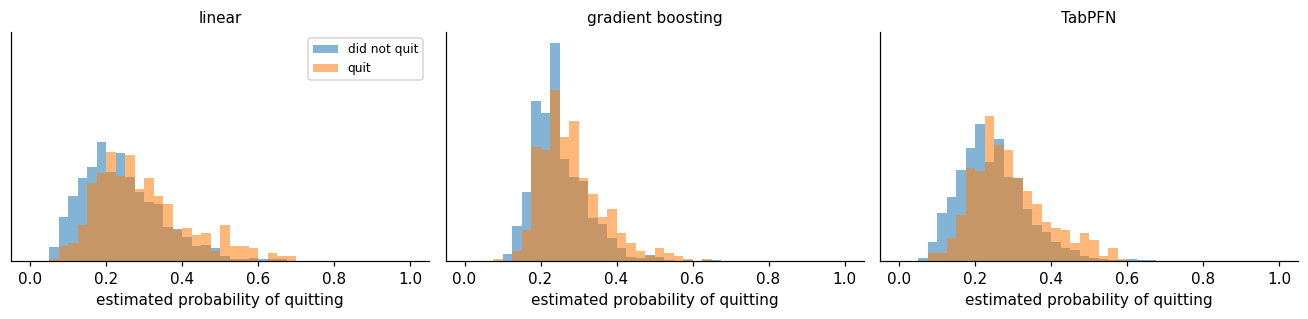

,propensity_min,propensity_max,share_extreme,effective_n_treated,effective_n_control
linear,0.050,0.700,0.0,329.810,1126.910
gradient boosting,0.097,0.664,0.0,372.918,1147.411
TabPFN,0.065,0.655,0.0,355.068,1140.024


In [8]:
helper.plot_overlap(t, {name: nu.e_raw for name, nu in nuisances.items()})
pd.DataFrame({name: overlap_summary(t, nu.e_raw) for name, nu in nuisances.items()}).T[
    ["propensity_min", "propensity_max", "share_extreme", "effective_n_treated", "effective_n_control"]].round(3)

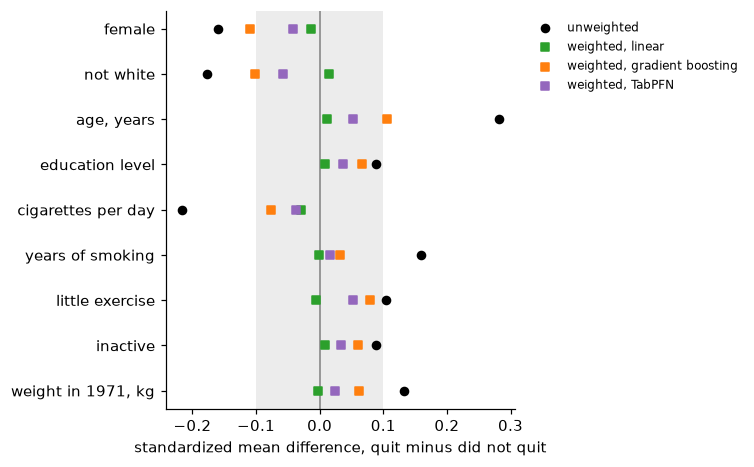

,unweighted,"weighted, linear","weighted, gradient boosting","weighted, TabPFN"
female,-0.160,-0.013,-0.109,-0.042
not white,-0.177,0.014,-0.101,-0.058
"age, years",0.282,0.011,0.106,0.052
education level,0.088,0.008,0.067,0.036
cigarettes per day,-0.217,-0.029,-0.077,-0.037
years of smoking,0.159,-0.001,0.032,0.016
little exercise,0.104,-0.005,0.079,0.053
inactive,0.089,0.009,0.060,0.033
"weight in 1971, kg",0.133,-0.002,0.062,0.024


In [9]:
balance = pd.DataFrame({"unweighted": raw_balance})
for name, nu in nuisances.items():
    w = np.where(t == 1, 1 / nu.e, 1 / (1 - nu.e))
    balance[f"weighted, {name}"] = pd.Series(standardized_differences(X_raw, t, weights=w, names=NHEFS_COVARIATES))
balance.index = [LABELS[c] for c in balance.index]
helper.plot_balance(balance)
balance.round(3)

Overlap is good with every model. Estimated probabilities of quitting run from about 0.05 to 0.70, nobody falls below 0.05 or above 0.95, and the weighted quitters are still worth 330 to 373 of the 403.

Balance after weighting separates the models a little more than their prediction errors did:

- **The linear model's weights** balance every covariate almost exactly, all standardized differences below 0.03. This is partly by construction: logistic regression's fitting equations make predicted and actual quitting agree on average for every term the model contains, which tends to balance those terms after weighting.
- **TabPFN's weights** leave every difference below 0.06, well inside the band.
- **Gradient boosting's weights** leave three just outside it: sex (−0.109), race (−0.101) and age (0.106). Its propensities predict quitting least well of the three, and this remaining imbalance is the visible consequence. It changes the average effect little here, because AIPW's outcome models correct for what the weights miss.

## 6. Who gains more?

The book's outcome model already allows the effect to change with the number of cigarettes smoked. The meta-learners of notebook 01 can let it change with everything: here the DR-learner and the X-learner, on each base model.

Without true effects, two checks ask whether the estimated differences between people are real:

- **The best linear predictor test.** The doubly robust pseudo-outcome of each person (the bracketed term of the AIPW formula, a noisy but unbiased signal of their effect) is regressed on their estimated effect. The slope, called the heterogeneity coefficient below, is 0 if the estimates say nothing about who gains more, and 1 if they are right on average about how much more; an interval that excludes 0 is evidence that the effect really differs between people.
- **Group averages.** People are split into fifths by their estimated effect, and the doubly robust average effect is computed within each fifth. If the estimates are informative, the averages rise from the lowest fifth to the highest.

Both checks use each base model's own cross-fitted pseudo-outcomes.

In [10]:
effects, pseudo, rows = {}, {}, []
for name, (regressor, classifier) in learners.items():
    nu = nuisances[name]
    pseudo[name] = dr_pseudo_outcome(t, y, nu)
    for method, tau in [("DR-learner", dr_learner(designs[name], t, y, nu, regressor, folds)),
                        ("X-learner", x_learner(designs[name], t, y, nu, regressor, folds))]:
        effects[(name, method)] = tau
        test = blp_test(pseudo[name], tau)
        low, high = test["heterogeneity"].interval()
        rows.append({"base model": name, "method": method, "spread of estimates (sd)": tau.std(),
                     "average effect": test["average"].estimate, "heterogeneity coefficient": test["heterogeneity"].estimate,
                     "95% interval": f"{low:.2f} to {high:.2f}"})
pd.DataFrame(rows).set_index(["base model", "method"]).round(3)

spread of estimates (sd)  average effect  heterogeneity coefficient   95% interval
base model        method                                                                                        
linear            DR-learner                     3.059           3.202                      0.142  -0.24 to 0.52
                  X-learner                      2.728           3.202                      0.491   0.05 to 0.93
gradient boosting DR-learner                     2.303           3.296                     -0.152  -0.85 to 0.55
                  X-learner                      1.548           3.296                      0.327  -0.48 to 1.13
TabPFN            DR-learner                     1.183           3.408                      0.014  -1.05 to 1.08
                  X-learner                      0.906           3.408                      0.301  -1.06 to 1.67

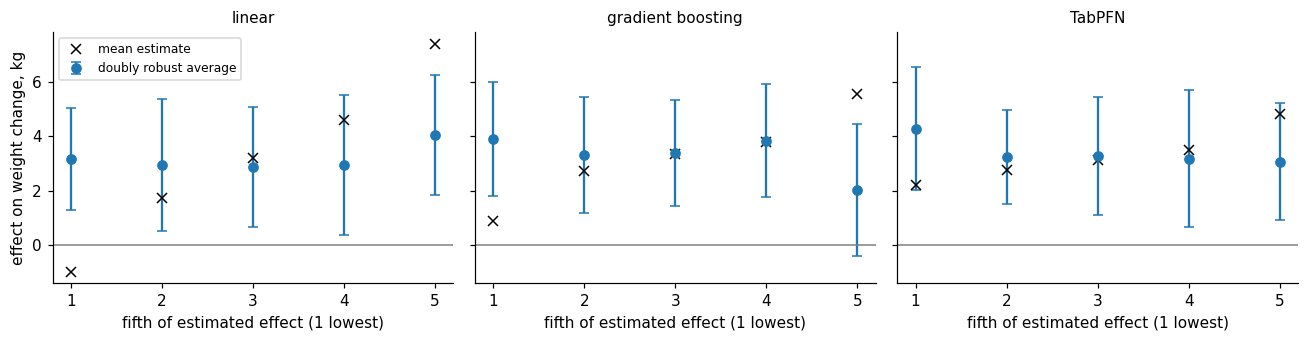

,linear,gradient boosting,TabPFN
fifth 1,3.17,3.89,4.28
fifth 2,2.96,3.31,3.23
fifth 3,2.89,3.41,3.28
fifth 4,2.95,3.84,3.18
fifth 5,4.05,2.02,3.07


In [11]:
helper.plot_gates({name: gates(pseudo[name], effects[(name, "DR-learner")]) for name in learners})
pd.DataFrame({name: [row["average"].estimate for row in gates(pseudo[name], effects[(name, "DR-learner")])] for name in learners},
             index=[f"fifth {g}" for g in range(1, 6)]).round(2)

**What the estimates depend on.** Each person's DR-learner estimate against three confounders the effect might plausibly depend on, and how much the three base models agree about who gains more (the correlation of their estimates across people).

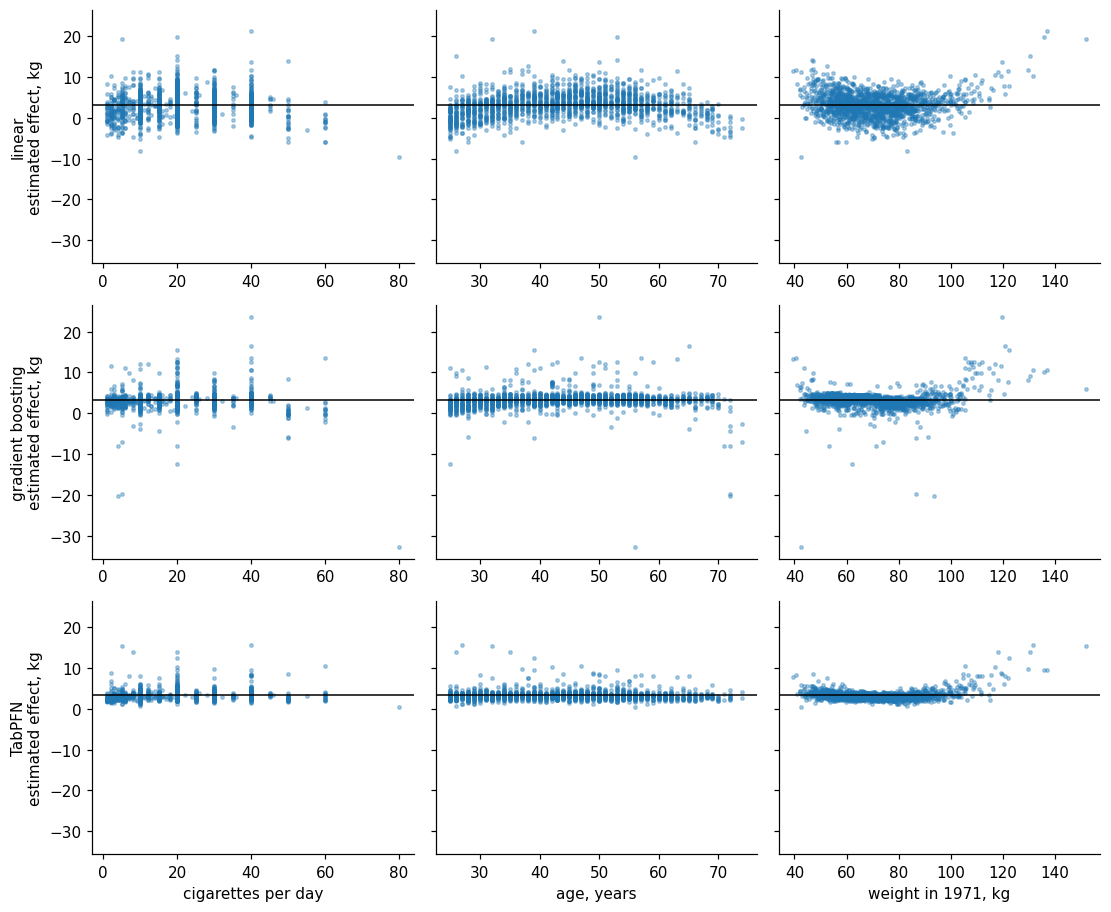

,linear,gradient boosting,TabPFN
linear,1.00,0.49,0.56
gradient boosting,0.49,1.00,0.51
TabPFN,0.56,0.51,1.00


In [12]:
dr_effects = {name: effects[(name, "DR-learner")] for name in learners}
helper.plot_effect_by_covariate(nhefs, dr_effects, ["smokeintensity", "age", "wt71"], LABELS)
pd.DataFrame(dr_effects).corr().round(2)

No base model finds differences between people that survive the checks:

- **The heterogeneity coefficient's 95% interval includes zero for five of the six estimators.** The sixth, the linear X-learner, gives 0.49 (0.05 to 0.93); one interval in six excluding zero is about what chance alone produces at this level.
- **The group averages are flat.** For TabPFN they run 4.28, 3.23, 3.28, 3.18 and 3.07 kg from the fifth with the lowest estimates to the fifth with the highest, each with a 95% interval about two kilograms either side: not rising, and well within each other's uncertainty. The other two models' fifths are just as flat.
- **The models' estimates disagree.** Their spread across people is 3.1 kg for the linear DR-learner, 2.3 kg for gradient boosting and 1.2 kg for TabPFN, and the three models' estimates correlate only 0.49 to 0.56. Most of that spread is noise passed on from the pseudo-outcomes, which TabPFN smooths the most; its estimates rise only for the heaviest people, above about 100 kg, who are 70 of the 1,566.

This is a limit of the data, not of the estimators. With 1,566 people whose weight changes vary by about 8 kg for reasons the confounders do not capture, a fifth of the sample pins its average effect down only to about two kilograms either way, so differences in the effect between people smaller than that cannot be detected. The book's interaction, 0.047 kg per cigarette a day, implies differences of about a kilogram between typical light and heavy smokers, below that resolution. Notebook 01 showed that TabPFN gives the most accurate individual effects when they can be estimated. This study shows the other side: an individual-effect model always produces estimates, and only checks like these say whether they mean anything.

## 7. How strong would an unmeasured confounder have to be?

Every estimate above assumes that the nine confounders are all there is: that nothing else both made people more likely to quit and changed their weight. That assumption cannot be tested from the data. What can be measured is how strong a missing confounder would have to be to change the conclusion. DoubleML implements the sensitivity analysis of Chernozhukov, Cinelli, Newey, Sharma and Syrgkanis (2022) for the doubly robust estimator. It describes a confounder by two numbers: how much of the remaining variation in weight change it would explain (`cf_y`), and how much it would add to the explanation of who quit (`cf_d`), each as a share between 0 and 1.

- The **robustness value** is the strength, the same share for both, at which the confounder would bring the estimate's bound down to zero; the version that also accounts for sampling noise is the strength at which the 95% interval would first include zero.
- **Benchmarks** make the shares concrete: each observed confounder is dropped in turn, and its own strength is measured as if it were the missing one. A missing confounder as strong as cigarettes per day, say, would be about as damaging as dropping cigarettes per day.

The analysis below uses the TabPFN version of the estimator.

In [13]:
regressor, classifier = learners["TabPFN"]
frame = nhefs[NHEFS_COVARIATES + ["qsmk", "wt82_71"]].reset_index(drop=True)
data = dml.DoubleMLData(frame, "wt82_71", "qsmk", NHEFS_COVARIATES)
sensitivity_model = dml.DoubleMLIRM(data, regressor(), classifier(), n_folds=N_FOLDS, trimming_threshold=0.01)
sensitivity_model.fit()
sensitivity_model.sensitivity_analysis(cf_y=0.03, cf_d=0.03, rho=1.0)
print(sensitivity_model.sensitivity_summary)

================== Sensitivity Analysis ==================

------------------ Scenario          ------------------
Significance Level: level=0.95
Sensitivity parameters: cf_y=0.03; cf_d=0.03, rho=1.0

------------------ Bounds with CI    ------------------
      CI lower  theta lower   theta  theta upper  CI upper
qsmk     2.231        3.059   3.597        4.135     4.961

------------------ Robustness Values ------------------
      H_0  RV (%)  RVa (%)
qsmk  0.0   18.39   14.394


In [14]:
benchmarks = {}
for column in ["smokeintensity", "age", "wt71", "smokeyrs"]:
    result = sensitivity_model.sensitivity_benchmark(benchmarking_set=[column])
    benchmarks[LABELS[column]] = result.iloc[0][["cf_y", "cf_d", "rho", "delta_theta"]].to_dict()
pd.DataFrame(benchmarks).T.round(3)

,cf_y,cf_d,rho,delta_theta
cigarettes per day,0.000,0.052,-1.000,-0.228
"age, years",0.029,0.025,-0.695,-0.328
"weight in 1971, kg",0.046,0.000,-1.000,-0.167
years of smoking,0.000,0.000,-1.000,-0.141


With DoubleML's own fold split, the TabPFN estimate is 3.60 kg. Its robustness value is 18.4%: a missing confounder would have to account for 18.4% of the remaining variation in weight change and the same share in quitting, in the sense of the two parameters above, to bring the estimate to zero. To make the 95% interval reach zero, 14.4% on both sides would do.

The benchmarks measure the observed confounders on the same scale. None exceeds 5.2% on either share: cigarettes per day reaches 5.2% on quitting but almost nothing on weight change, weight in 1971 reaches 4.6% on weight change but almost nothing on quitting, and age, the only one noticeably related to both, is at 2.9% and 2.5%. Dropping any one of them moves the estimate by 0.14 to 0.33 kg. A missing confounder would therefore have to be several times as strong as any confounder measured, on both sides at once, to make the effect disappear. The printed scenario, a confounder at 3% on both sides, about as strong as age, would leave the estimate between 3.06 and 4.14 kg and its 95% interval between 2.23 and 4.96 kg.

So the conclusion that quitting causes weight gain survives any unmeasured confounder of the strength of the ones measured. Its size, about 3.5 kg, is less certain: such a confounder could move it by about half a kilogram either way.

## What this leaves open

- **The people with no 1982 weight.** The 63 people without an outcome are dropped, as in the book's first analyses. The book also weights for their absence and gets about 3.5 kg; doing the same with the three base models is a small extension.
- **A study where the base model matters.** The base models agree here because the nine confounders carry little information about weight change. Whether TabPFN's accuracy advantage from notebook 01 shows on real data needs a study whose covariates predict the outcome well.
- **Intervals for individual effects** remain to be built and checked, now with a real case in which the honest answer is that differences between people cannot be resolved.
- **A trial as the ground truth.** Notebook 03 builds observational studies out of a randomized trial, so the same estimators can be scored against a real answer rather than a simulated or published one.